# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATReset_Friday_1458.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'])

In [6]:
data['result'] = data['info'].str.split(';').str[0].where(data.solved, 'Unsolved')

In [7]:
strategies = data.strategy.unique()
strategies

array(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveLiteral',
       'SATResetAtStaleAction', 'SATResetAtStaleBacktrack',
       'SATResetBandit'], dtype=object)

In [8]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [9]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [10]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BIO', 'BOO', 'CAT', 'COL', 'COM', 'CSR',
       'FLD', 'GEO', 'GRA', 'GRP', 'HAL', 'HEN', 'HWC', 'HWV', 'KLE',
       'KRS', 'LAT', 'LCL', 'LDA', 'MED', 'MGT', 'MSC', 'NLP', 'NUM',
       'NUN', 'PHI', 'PLA', 'PRO', 'PUZ', 'REL', 'RNG', 'ROB', 'SCT',
       'SET', 'SEU', 'SEV', 'SWB', 'SWC', 'SWV', 'SWW', 'SYN', 'SYO',
       'TOP'], dtype=object)

# Analysing

In [11]:
control = ['FirstAction', 'LeanCopCut']

In [12]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error,result
0,AGT002+2.p,FirstAction,solved,True,5147.0,3470.0,Theorem,NaN,Theorem
1,AGT002+2.p,LeanCopCut,solved,True,5147.0,3471.0,Theorem,NaN,Theorem
2,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
3,AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
4,AGT002+2.p,SATResetAtStaleAction,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleAct...,NaN,Theorem (SAT)
...,...,...,...,...,...,...,...,...,...
9382,SYN971+1.p,SATSolve,solved,True,5.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
9383,SYN971+1.p,SATSolveLiteral,solved,True,5.0,0.0,"Theorem (SAT); literal=choices:4,forward:5,uni...",NaN,Theorem (SAT)
9384,SYN971+1.p,SATResetAtStaleAction,solved,True,5.0,0.0,"Theorem (SAT); literal=choices:4,forward:5,uni...",NaN,Theorem (SAT)
9385,SYN971+1.p,SATResetAtStaleBacktrack,solved,True,5.0,0.0,"Theorem (SAT); literal=choices:4,forward:5,uni...",NaN,Theorem (SAT)


In [13]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                 178
LeanCopCut                  177
SATResetAtStaleAction       276
SATResetAtStaleBacktrack    277
SATResetBandit              255
SATSolve                    159
SATSolveLiteral             243
dtype: int64

# Results

<Axes: xlabel='strategy'>

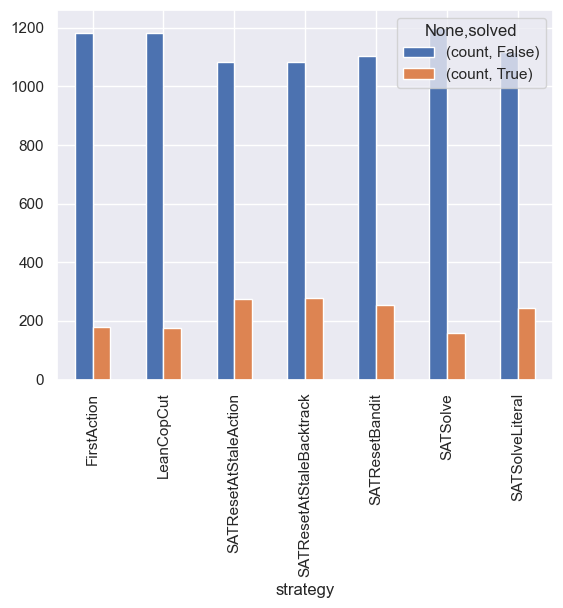

In [14]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

In [15]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [16]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCopCut,SATResetAtStaleAction,SATResetAtStaleBacktrack,SATResetBandit,SATSolve,SATSolveLiteral
strategy_left,,,,,,,
FirstAction,1360,1360,1360,1360,1360,1360,1360
LeanCopCut,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleAction,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleBacktrack,1360,1360,1360,1360,1360,1360,1360
SATResetBandit,1360,1360,1360,1360,1360,1360,1360
SATSolve,1360,1360,1360,1360,1360,1360,1360
SATSolveLiteral,1360,1360,1360,1360,1360,1360,1360


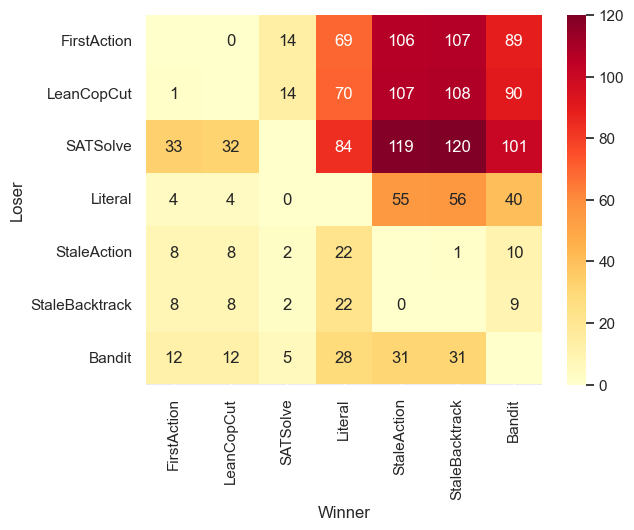

In [17]:
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = merged.strategy_left.unique(), columns = merged.strategy_left.unique(), fill_value = 0)
)

renamer = {
    'SATSolve': 'SATSolve',
    'SATSolveLiteral': 'Literal',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
}


cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
)
# pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
pyplot.savefig('figures/sat_policies_plot_29Apr.png', bbox_inches = 'tight', dpi = 400)

# Analysis

In [18]:
merged[~merged.solved_left & merged.solved_right].loc[lambda x: (x.strategy_left == 'SATResetAtStaleAction') & (x.strategy_right == 'SATResetAtStaleBacktrack')]

,problem,strategy_left,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,result_left,strategy_right,status_right,solved_right,steps_right,time_ms_right,info_right,error_right,result_right
34088,NUM508+3.p,SATResetAtStaleAction,timeout,False,5158.0,120010.0,"score=1.0; literal=choices:4460,forward:592870...",NaN,Unsolved,SATResetAtStaleBacktrack,solved,True,5345.0,111125.0,Theorem (SAT); score=1.0; literal=choices:4626...,NaN,Theorem (SAT)


In [22]:
data.groupby('strategy').result.value_counts()

strategy                  result       
FirstAction               Unsolved         1182
                          Theorem (SAT)     103
                          Theorem            75
LeanCopCut                Unsolved         1183
                          Theorem (SAT)     102
                          Theorem            75
SATResetAtStaleAction     Unsolved         1084
                          Theorem (SAT)     276
SATResetAtStaleBacktrack  Unsolved         1083
                          Theorem (SAT)     277
SATResetBandit            Unsolved         1105
                          Theorem (SAT)     255
SATSolve                  Unsolved         1201
                          Theorem (SAT)     159
SATSolveLiteral           Unsolved         1117
                          Theorem (SAT)     243
Name: count, dtype: int64

In [26]:
data[(data.strategy == 'LeanCopCut') & (data['info'].str.startswith('Theorem (SAT)'))]

,problem,strategy,status,solved,steps,time_ms,info,error,result
680,COM007+1.p,LeanCopCut,solved,True,26358.0,21997.0,Theorem (SAT),NaN,Theorem (SAT)
687,COM012+1.p,LeanCopCut,solved,True,58084.0,13149.0,Theorem (SAT),NaN,Theorem (SAT)
876,CSR062+1.p,LeanCopCut,solved,True,3397.0,333.0,Theorem (SAT),NaN,Theorem (SAT)
883,CSR070+1.p,LeanCopCut,solved,True,3524.0,344.0,Theorem (SAT),NaN,Theorem (SAT)
1079,FLD019-3.p,LeanCopCut,solved,True,17977.0,5293.0,Theorem (SAT),NaN,Theorem (SAT)
...,...,...,...,...,...,...,...,...,...
8933,SYN397+1.p,LeanCopCut,solved,True,24.0,1.0,Theorem (SAT),NaN,Theorem (SAT)
9136,SYN575-1.p,LeanCopCut,solved,True,17707.0,6245.0,Theorem (SAT),NaN,Theorem (SAT)
9199,SYN729-1.p,LeanCopCut,solved,True,321.0,27.0,Theorem (SAT),NaN,Theorem (SAT)
9360,SYN942+1.p,LeanCopCut,solved,True,17.0,1.0,Theorem (SAT),NaN,Theorem (SAT)
